### *Algoritmos Genéticos y Optimización Heurística - UTN-FRT*

# **Trabajo Práctico N°3**
### Tema: Operadores Genéticos

***Integrantes***

*   Breslauer, León - 56340
*   Perez, Francisco - 56355



## Ejercicio 1
Implemente el operador de selección con Ruleta con pesos, completando el código dado.

In [4]:
import random

def sel_ruleta(F, cant_selectos, eps):
    """ Operador de selección por ruleta con pesos.
    Parametros:
    F: list
        Lista de valores de fitness de cada individuo de la población.
    cant_selectos: int
        Cantidad de individuos a seleccionar.
    eps: float
        Valor de fitness normalizado para el peor individuo.
    S: list
        Lista con las POSICIONES de los individuos seleccionados.
    """
    # 1) Normalizar el fitness: el peor individuo queda con valor eps (> 0),
    #    así todos tienen alguna chance y funciona con fitness negativos.
    min_f = min(F) # También puede ser F[-1]
    f_norm = [fi - min_f + eps for fi in F]

    # 2) Probabilidad de cada individuo, proporcional a su fitness normalizado
    total = sum(f_norm)
    probs = [fi / total for fi in f_norm]

    # 3) Obtener las probabilidades acumuladas de cada individuo
    cum_probs = []
    suma = 0.0
    for p in probs:
        suma += p
        cum_probs.append(suma)

    S = random.choices(range(len(F)), cum_weights=cum_probs, k=cant_selectos)

    return S


# PRUEBA

F = [0.54, 0.28, 0.16, 0.12]
eps = 0.2
cant_tiros = 2

#aplicar seleccion
sel = sel_ruleta(F, cant_tiros, eps)

print('Posicion de individuos seleccionados:')
print(sel)


Posicion de individuos seleccionados:
[0, 1]


### Otras soluciones posibles

**Muestreo Estocástico Universal (SUS)**: Operador de selección ***con reposición***. Utiliza una única tirada aleatoria en $[0, 1/k]$ y avanza con punteros equiespaciados a distancia $1/k$ sobre las probabilidades acumuladas.

In [2]:
import random

def sel_sus(F, cant_selectos, eps=0.2):
    """ Operador de selección por Muestreo Estocástico Universal (SUS) - Con Reposición.
    Parámetros:
    F: list - Lista de valores de fitness de cada individuo.
    cant_selectos: int - Cantidad de individuos a seleccionar (punteros).
    eps: float - Valor de fitness normalizado para el peor individuo (> 0).
    Retorna:
    S: list - Lista con las POSICIONES de los individuos seleccionados.
    """
    # 1) Normalizar el fitness sin alterar el orden original de F
    min_f = min(F)
    f_norm = [fi - min_f + eps for fi in F]

    # 2) Probabilidad proporcional al fitness normalizado
    total = sum(f_norm)
    probs = [fi / total for fi in f_norm]

    # 3) Probabilidades acumuladas
    cum_probs = []
    suma = 0.0
    for p in probs:
        suma += p
        cum_probs.append(suma)

    # 4) Generar un único punto de arranque en [0, 1/cant_selectos) y avanzar de a pasos constantes
    paso = 1.0 / cant_selectos
    inicio = random.uniform(0, paso)
    punteros = [inicio + i * paso for i in range(cant_selectos)]

    S = []
    idx = 0
    # Recorrido lineal O(N): como los punteros están ordenados, no hace falta reiniciar idx
    for p in punteros:
        while cum_probs[idx] < p:
            idx += 1
        S.append(idx)

    return S

## Ejercicio 2
Genere un histograma que muestre la probabilidad de ser seleccionado de cada individuo (basado en su fitness), y un histograma con la cantidad de veces que cada individuo es efectivamente seleccionado. Utilice una población con 10 individuos y el operador de seleccion implementado en el punto anterior sobre la función de evaluación f(x,y) = -sum(x^2 + y^2). ¿Qué diferencia hay al seleccionar 10, 100 y 1000 tiros con el operador dado?

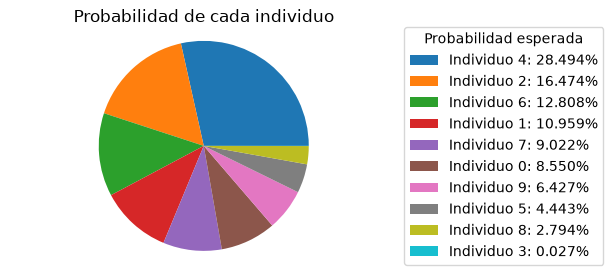

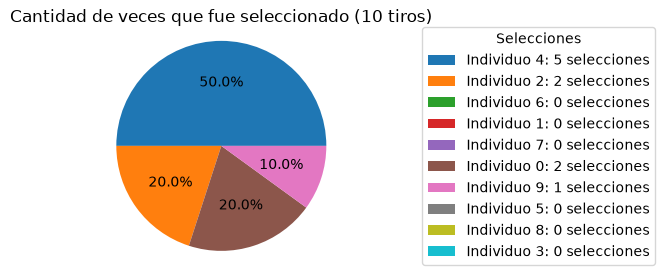

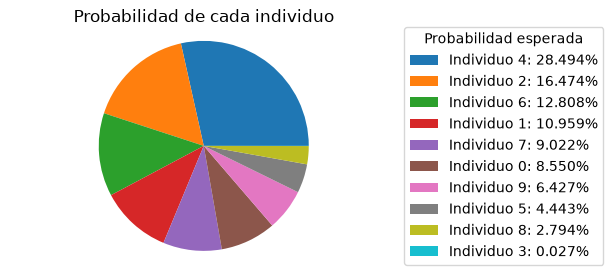

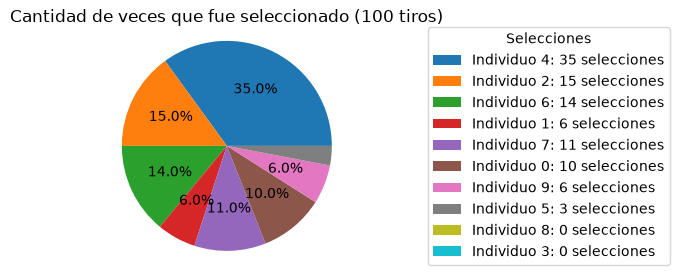

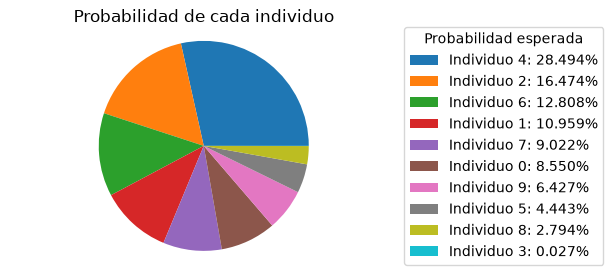

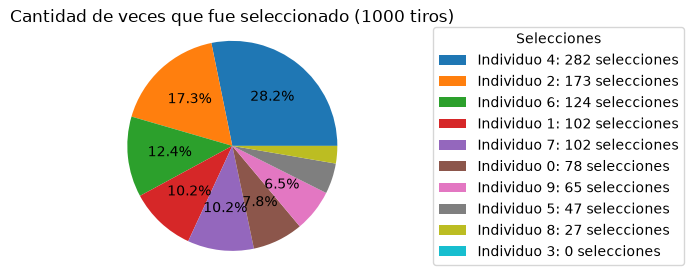

In [9]:
import random
import matplotlib.pyplot as plt


# Hicimos un cambio aquí con respecto a lo que nos dieron los profesores porque
# nos pareció más adecuado utilizar un gráfico de tortas.
# Aclaramos, esto no influye en nada en el funcionamiento del algoritmo.
# Si lo corres X veces, siempre dará la misma probabilidad ya que depende de cosas
# deterministicas y el "Fitness" no cambia para una misma corrida, por eso el
# gráfico es igual
def histograma(pop, fitness, p_selectos, eps):
    # 1) Probabilidad teórica de cada individuo
    min_f = min(fitness)
    f_norm = [fi - min_f + eps for fi in fitness]
    sum_f = sum(f_norm)
    prob = [fi / sum_f for fi in f_norm]

    # 2) Cantidad absoluta y relativa de selecciones
    c = [0] * len(prob)
    for p in p_selectos:
        c[p] += 1

    cant = [ci / len(p_selectos) for ci in c]

    # 3) Orden para graficar
    psort = sorted(range(len(prob)), key=lambda k: prob[k], reverse=True)

    # 4) Mostrar porcentaje dentro de la torta solo si es >= 5%
    def autopct_format(values):
        def formatter(pct):
            if pct >= 5:
                return f'{pct:.1f}%'
            else:
                return ''
        return formatter

    # 5) Torta 1: probabilidad esperada
    plt.figure()

    valores_prob = [prob[p] for p in psort]
    labels_prob = [f'Individuo {p}: {prob[p]*100:.3f}%' for p in psort]

    plt.pie(
        valores_prob,
        labels=None,
        startangle=0
    )

    plt.legend(
        labels_prob,
        title='Probabilidad esperada',
        loc='center left',
        bbox_to_anchor=(1, 0.5)
    )

    plt.title('Probabilidad de cada individuo')
    plt.axis('equal')

    # 6) Torta 2: cantidad efectiva de selecciones
    plt.figure()

    valores_cant = [cant[p] for p in psort]
    labels_cant = [f'Individuo {p}: {c[p]} selecciones' for p in psort]

    plt.pie(
        valores_cant,
        labels=None,
        autopct=autopct_format(valores_cant),
        startangle=0
    )

    plt.legend(
        labels_cant,
        title='Selecciones',
        loc='center left',
        bbox_to_anchor=(1, 0.5)
    )

    plt.title('Cantidad de veces que fue seleccionado')
    plt.axis('equal')

    #print(f'f_norm: {f_norm}')
    #print(f'prob: {prob}')
    #print(f'p_selectos: {p_selectos}')
    #print(f'cant: {cant}')
    #print(f'psort: {psort}')
    #print(f'valores_prob: {valores_prob}')
    #print(f'valores_cant: {valores_cant}\n')

def generar_poblacion(bounds, cant_soluciones):
    pop = []
    for i in range(cant_soluciones):
        s = [random.random() * (b[1] - b[0]) + b[0] for b in bounds]
        pop.append(s)
    return pop

def fitness(S):
    return -sum([xi**2 for xi in S])

plt.rcParams['figure.figsize'] = (5, 3)

# PRUEBA
random.seed(1)

cant_soluciones = 10
cant_tiros = 10
eps = 0.1
bounds = [[0,10], [0,10]] #2 coordenadas

#generar una poblacion de individuos de prueba
pop = generar_poblacion(bounds, cant_soluciones)
#evaluar cada individuo
F = [fitness(s) for s in pop]
#aplicar seleccion con 10, 100 y 1000 tiros sobre la MISMA poblacion
for cant_tiros in [10, 100, 1000]:
    sel = sel_ruleta(F, cant_tiros, eps)
    histograma(pop, F, sel, eps)
    plt.title(f'Cantidad de veces que fue seleccionado ({cant_tiros} tiros)')
plt.show()



**Respuesta:** el primer histograma (probabilidad) es el mismo en los tres casos, porque depende solo del fitness de cada individuo. Los primeros individuos, que son los que mayor valor de fitness tienen, siempre se ubican en los primeros lugares de la distribución acumulada (la ruleta) y, por lo tanto,  abarcarán la mayor superficie de esta. Sin embargo, en dicho histograma, no se está teniendo en cuenta la cantidad de veces que salió cada individuo (dicho de otra forma, la frecuencia real de selección). Esta última consideración es lo que hace que el segundo gráfico cambie de acuerdo a la cantidad de tiros realizados:

- **10 tiros:** la distribución es muy irregular; algunos individuos con alto valor de fitness pueden no salir nunca y otros con peor fitness salir más de lo esperado.
- **100 tiros:** la forma del histograma ya se parece a la de las probabilidades, aunque con desvíos visibles (por ejemplo, el individuo 5 salió más veces que el 3, cuando este último tiene mayor probabilidad de ser elegido).
- **1000 tiros:** la frecuencia relativa converge a la probabilidad teórica (ley de los grandes números) y ambos histogramas son casi iguales; el segundo gráfico casi respeta fielmente el algoritmo de selección según el valor de fitness.

Conclusión: la ruleta respeta las probabilidades solo en promedio. Con pocos tiros, como en una población chica, la selección tiene mucha variación.

In [ ]:
import matplotlib.pyplot as plt

# Suponiendo que ya tenés calculado tu vector F de 10 individuos del Ejercicio 2:
# Ordenamos F y P juntos de mayor a menor fitness para que el gráfico quede limpio como en tu TP:
F_ordenado = sorted(F, reverse=True)
eps = 0.2
cant_tiros = 100 # Probá cambiar a 10, 100 y 1000

operadores = {
    "Ruleta (Con Rep)": lambda: sel_ruleta(F_ordenado.copy(), cant_tiros, eps),
    "SUS (Con Rep)": lambda: sel_sus(F_ordenado, cant_tiros, eps),
    "Torneo k=2 (Con Rep)": lambda: sel_torneo_con_rep(F_ordenado, cant_tiros, tam_torneo=2),
    "Torneo k=2 (Sin Rep)": lambda: sel_torneo_sin_rep(F_ordenado, cant_tiros, tam_torneo=2),
    "Ruleta (Sin Rep)": lambda: sel_ruleta_sin_rep(F_ordenado, cant_tiros, eps)
}

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
bins = [i - 0.5 for i in range(len(F_ordenado) + 1)]

for ax, (nombre, func_sel) in zip(axes, operadores.items()):
    seleccionados = func_sel()
    ax.hist(seleccionados, bins=bins, rwidth=0.8, color='steelblue', edgecolor='black')
    ax.set_title(nombre, fontsize=11)
    ax.set_xticks(range(len(F_ordenado)))
    ax.set_xlabel("Individuo")
    ax.grid(axis='y', linestyle='--', alpha=0.5)

axes[0].set_ylabel(f"Frecuencia ({cant_tiros} tiros)")
plt.tight_layout()
plt.show()

## Ejercicio 3
Implemente el operador Uniform crossover, completando el código. Luego apliquelos a los dos individuos dados.

In [ ]:
import random

def xov_uniform(P1, P2):
    """Operador Uniform Crossover para Algoritmos Geneticos.
    Parametros:
    P1: list
        Lista correspondiente a uno de los individuos padres a cruzar.
    P2: list
        Lista correspondiente a uno de los individuos padres a cruzar.
    """
    C1, C2 = [], []
    # Para cada gen se tira una moneda: con prob. 0.5 los hijos lo heredan
    # tal cual de sus padres, si no, se intercambian.
    for g1, g2 in zip(P1, P2):
        if random.random() < 0.5:
            C1.append(g1)
            C2.append(g2)
        else:
            C1.append(g2)
            C2.append(g1)

    return C1, C2 #devolver listas del mismo tamaño que P1 y P2

P1 = [2.1, 9.3, 7.4, 1.8, 5.2]
P2 = [4.2, 1.6, 2.7, 6.4, 5.9]
print("Individuos Padres")
print(P1)
print(P2)

C1, C2 = xov_uniform(P1, P2)
print("Uniform Crossover")
print(C1)
print(C2)


Individuos Padres
[2.1, 9.3, 7.4, 1.8, 5.2]
[4.2, 1.6, 2.7, 6.4, 5.9]
Uniform Crossover
[2.1, 1.6, 7.4, 6.4, 5.9]
[4.2, 9.3, 2.7, 1.8, 5.2]


## Ejercicio 4
Implemente los siguientes operadores de mutación completando el código dado.
1. Boundary Mutation
2. Step Mutation

In [ ]:
import random

def mut_boundary(P, Bounds):
    """Boundary Mutation
    Parámetros
    P: list
        Vector correspondiente a un individuo.
    Bounds: list
        Matriz que indica los valores maximo y minimo de cada coordenada.
    """
    C = P.copy()
    cut = random.randint(0, len(P)-1)
    C[cut] = Bounds[cut][random.randint(0, 1)]
    return C

def mut_step(P, Bounds):
    """Step Mutation
    Parámetros
    P: list
        Vector correspondiente a un individuo.
    Bounds: list
        Matriz que indica los valores maximo y minimo de cada coordenada.
    """
    C = P.copy()
    # Elegir una coordenada al azar del individuo seleccionado.
    i = random.randint(0, len(P)-1)
    # Elegir una dirección de cambio (hacia el máximo o hacia el mı́nimo)
    bound = random.randint(0, 1)
    dir_limit = Bounds[i][bound]
    # Elegir un valor al azar intermedio entre el valor actual y el valor extremo seleccionado
    C[i] = random.uniform(C[i], dir_limit) if C[i] <= dir_limit else random.uniform(dir_limit, C[i])
    C[i] = round(C[i], 1)

    return C #devolver lista del mismo tamaño que P

P = [2.1, 9.3, 7.4, 1.8, 5.2]
bounds = [[0,10], [0,10], [0,10], [0,10], [0,10]]

print("Individuo original")
print(P)

C = mut_boundary(P, bounds)
print("Boundary Mutation")
print(C)

C = mut_step(P, bounds)
print("Step Mutation")
print(C)


Individuo original
[2.1, 9.3, 7.4, 1.8, 5.2]
Boundary Mutation
[2.1, 9.3, 7.4, 1.8, 0]
Step Mutation
[2.1, 9.7, 7.4, 1.8, 5.2]


## Conclusiones

- **Selección por ruleta con pesos:** asigna a cada individuo una probabilidad proporcional a su fitness normalizado. Restar el mínimo y sumar `eps` permite trabajar con fitness negativos (como en f(x,y) = -(x² + y²)) y garantiza que hasta el peor individuo conserve una chance mínima, lo que ayuda a mantener la diversidad. Un `eps` chico aumenta la presión selectiva y uno grande la reduce, acercándose a una selección aleatoria.
- **Cantidad de tiros:** la ruleta es un operador estocástico. Con 10 tiros la frecuencia observada se aleja bastante de la probabilidad teórica, con 100 se aproxima y con 1000 prácticamente coinciden. En poblaciones chicas esto implica que un buen individuo puede perderse por azar (deriva genética), y conviene combinar la ruleta con elitismo o usar variantes de menor varianza, como el muestreo universal estocástico.
- **Uniform crossover:** cada gen se hereda de uno u otro padre con probabilidad 0,5, así que mezcla la información de forma más fina que el cruce de uno o dos puntos y no depende de la posición de los genes. Es muy explorador, aunque puede romper combinaciones de genes que funcionaban bien juntas.
- **Boundary mutation:** lleva una coordenada a su límite inferior o superior. Es útil cuando el óptimo está en el borde del dominio, pero es un cambio brusco que puede alejar al individuo de una buena zona.
- **Step mutation:** cambia el valor de una coordenada a un valor intermedio entre su valor actual y el de un límite inferior o superior. El cambio puede llegar a ser menos brusco que en el caso de Boundary Mutation, pero eso depende de si el valor actual de la coordenada no se encuentra demasiado alejado del límite elegido

Aún no hemos aplicado estos operadores dentro de un algoritmo genético. No obstante, se comprende que cumplen funciones complementarias: la selección determina qué individuos participan en la reproducción, el crossover recombina información genética existente y la mutación introduce nueva variabilidad. En consecuencia, la calidad de un algoritmo genético depende de la combinación adecuada de estos operadores y del ajuste de sus parámetros, más que del uso exhaustivo de todas las variantes disponibles.